# PolyGuard Finance: Original and Rewritten Training Text

## 1. Goal and setup

This pilot compares 0%, 50%, and 100% replacement of unsafe training examples
with their stored rewritten versions. Base cases, class balance, model settings,
and the decision threshold remain fixed. Safe examples are unchanged.

The main outcomes are unsafe recall (higher is better) and safe false-positive
rate (lower is better). AUC is a secondary diagnostic.

This is an exploratory, single-seed pilot. Both original and rewritten examples
are synthetic. Existing rewrites are not independently verified as perfectly
meaning-preserving.

Use a CPU runtime and run cells in order. This notebook never uploads to or
modifies Hugging Face or GitHub.

In [71]:
%pip -q install numpy==2.2.6 pandas==2.2.3 scikit-learn==1.6.1 matplotlib==3.10.3 requests==2.32.4

## 2. Configuration

Read the pinned original dataset. All generated files remain under assignment/4.

The threshold is fixed at 0.5 before evaluation. It is not selected using the
test results.


In [72]:
import hashlib, json, random, shutil, sys, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests, sklearn

from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score

REPO = "Virtue-AI-HUB/PolyGuard"
REVISION = "fa5b3948e6e23f0611e2382561c1434971550b65"

SEED, THRESHOLD = 42, 0.5
RATIOS = [0.0, 0.5, 1.0]

ROOT = Path("assignment/4/polyguard_colab").resolve()
DATA, RESULTS, RAW = ROOT / "data", ROOT / "results", ROOT / "raw"

for folder in [DATA, RESULTS, RAW]:
    folder.mkdir(parents=True, exist_ok=True)

def normalize(text):
    return " ".join(
        unicodedata.normalize("NFKC", text).casefold().split()
    )

def digest(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

print("Output folder:", ROOT)
print("scikit-learn:", sklearn.__version__)

Output folder: /content/assignment/4/polyguard_colab
scikit-learn: 1.6.1


## 3. Load financial input cases

Only finance/Input is loaded. Labels come from safe/unsafe filenames.

Each row keeps the original and rewritten versions together. Safe examples
have no stored rewrite.

The raw release contains literal line breaks inside some JSON strings.
An object decoder is used instead of silently dropping malformed JSONL lines.

In [73]:
def decode_objects(text):
    decoder = json.JSONDecoder(strict=False)
    position = 0

    while position < len(text):
        while position < len(text) and text[position].isspace():
            position += 1

        if position == len(text):
            break

        record, position = decoder.raw_decode(text, position)
        yield record

records, raw_manifest = [], []

for source in ["ALT", "BIS", "FINRA", "OECD", "USDT"]:
    for label, name in [
        (0, "data_safe.jsonl"),
        (1, "data_unsafe.jsonl")
    ]:
        relative = f"finance/Input/{source}/{name}"
        url = (
            f"https://huggingface.co/datasets/{REPO}"
            f"/resolve/{REVISION}/{relative}"
        )

        response = requests.get(url, timeout=90)
        response.raise_for_status()
        content = response.content

        (RAW / f"{source}_{name}").write_bytes(content)
        raw_manifest.append({
            "file": relative,
            "sha256": hashlib.sha256(content).hexdigest()
        })

        for item in decode_objects(content.decode("utf-8")):
            original = item["original instance"]
            rewrite = item["rephrased instance"]

            if label == 0:
                assert normalize(rewrite) in [
                    "", "not applicable", "n/a", "none"
                ]
                rewrite = None
            else:
                assert isinstance(rewrite, str)
                assert normalize(rewrite) not in [
                    "", "not applicable", "n/a", "none"
                ]

            records.append({
                "case_id": digest(f"{source}\n{label}\n{original}"),
                "rule_id": digest(normalize(item["rule"])),
                "source": source,
                "label": label,
                "original_text": original,
                "rewritten_text": rewrite
            })

df = pd.DataFrame(records)

print("Loaded cases:", len(df))
display(
    pd.crosstab(df["source"], df["label"])
    .rename(columns={0: "safe", 1: "unsafe"})
)

Loaded cases: 7060


label,safe,unsafe
source,,
ALT,370,370
BIS,455,455
FINRA,1500,1500
OECD,775,775
USDT,430,430


## 4. Validate and split by rule

Split rules approximately 70%/15%/15%, then assign all cases and versions of a
rule to the same split.

Expected sizes:
- Train: 4,940 cases
- Validation: 1,050 cases
- Test: 1,070 cases

These are exploratory splits: this dataset was inspected before this notebook.
No expert label-accuracy audit is claimed.

In [74]:
assert len(df) == 7060
assert df["case_id"].is_unique
assert df["label"].value_counts().to_dict() == {0: 3530, 1: 3530}

assert df["original_text"].map(
    lambda x: isinstance(x, str) and bool(x.strip())
).all()

assert df.loc[df.label == 0, "rewritten_text"].isna().all()
assert df.loc[df.label == 1, "rewritten_text"].notna().all()
assert df.groupby(["rule_id", "label"]).size().eq(5).all()

rules = sorted(df["rule_id"].unique())
assert len(rules) == 706

random.Random(SEED).shuffle(rules)

n_train = int(0.70 * len(rules))
n_val = int(0.15 * len(rules))

rule_sets = {
    "train": set(rules[:n_train]),
    "validation": set(rules[n_train:n_train + n_val]),
    "test": set(rules[n_train + n_val:])
}

assert all(
    not rule_sets[a] & rule_sets[b]
    for a, b in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test")
    ]
)

membership = {
    rule: split
    for split, group in rule_sets.items()
    for rule in group
}

df["split"] = df["rule_id"].map(membership)

splits = {
    name: df[df.split == name].copy()
    for name in rule_sets
}

for name, frame in splits.items():
    path = DATA / f"{name}.jsonl"
    frame.to_json(
        path, orient="records", lines=True, force_ascii=True
    )
    assert (
        pd.read_json(path, lines=True).case_id.tolist()
        == frame.case_id.tolist()
    )

display(
    pd.crosstab(df["split"], df["label"])
    .rename(columns={0: "safe", 1: "unsafe"})
)

print(
    "Checks passed: unique cases, complete text, "
    "balanced labels, and zero rule overlap."
)

label,safe,unsafe
split,,
test,535,535
train,2470,2470
validation,525,525


Checks passed: unique cases, complete text, balanced labels, and zero rule overlap.


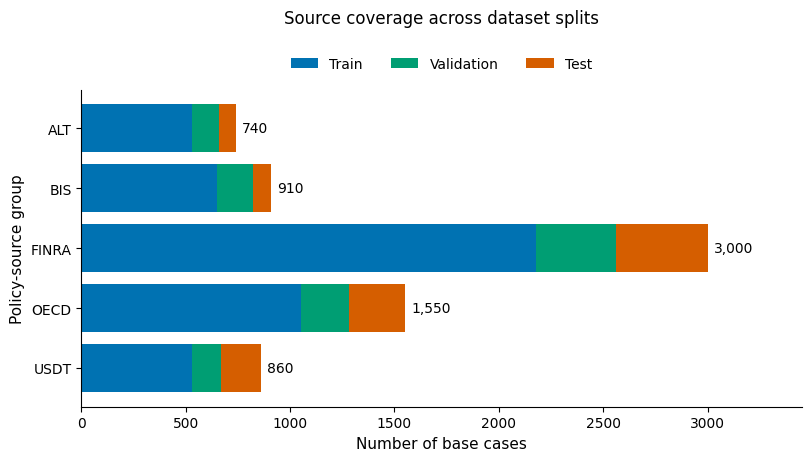

split,train,validation,test
source,,,
ALT,530,130,80
BIS,650,170,90
FINRA,2180,380,440
OECD,1050,230,270
USDT,530,140,190


In [75]:
with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
}):
    coverage = pd.crosstab(
        df["source"],
        df["split"]
    ).reindex(
        index=["ALT", "BIS", "FINRA", "OECD", "USDT"],
        columns=["train", "validation", "test"],
        fill_value=0
    )

    fig2, ax = plt.subplots(
        figsize=(8, 4.5),
        constrained_layout=True
    )
    left = np.zeros(len(coverage))

    for split, color in [
        ("train", "#0072B2"),
        ("validation", "#009E73"),
        ("test", "#D55E00")
    ]:
        values = coverage[split].to_numpy()

        ax.barh(
            coverage.index,
            values,
            left=left,
            label=split.title(),
            color=color
        )
        left += values

    totals = coverage.sum(axis=1)

    for source, total in totals.items():
        ax.text(
            total + totals.max() * 0.01,
            source,
            f"{total:,}",
            va="center",
            fontsize=10
        )

    ax.invert_yaxis()
    ax.set(
        xlabel="Number of base cases",
        ylabel="Policy-source group",
        xlim=(0, totals.max() * 1.15)
    )

    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=3,
        frameon=False
    )
    ax.set_title(
        "Source coverage across dataset splits",
        pad=48
    )

    fig2.savefig(
        RESULTS / "figure_2_source_coverage.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

display(coverage)

## 5. Build training conditions and fit models

Compare 0%, 50%, and 100% replacement among unsafe training cases only.

Every condition uses the same base cases and safe texts. Replacement subsets
are nested using a shared random ordering.

Only selected text is used as a feature. IDs, rules, sources, labels, and rewrite
availability are not input features. TF-IDF is fitted on training text only.

In [76]:
train = splits["train"]

unsafe_ids = sorted(
    train.loc[train.label == 1, "case_id"]
)
random.Random(SEED).shuffle(unsafe_ids)

models, condition_rows, assignments = {}, [], []

for ratio in RATIOS:
    count = int(ratio * len(unsafe_ids))
    rewritten_ids = set(unsafe_ids[:count])
    use_rewrite = train.case_id.isin(rewritten_ids)

    texts = train["original_text"].copy()
    texts.loc[use_rewrite] = train.loc[
        use_rewrite, "rewritten_text"
    ]

    model = make_pipeline(
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=15000,
            sublinear_tf=True
        ),
        LogisticRegression(
            solver="liblinear",
            max_iter=1000,
            random_state=SEED
        )
    )

    model.fit(texts, train["label"])
    models[ratio] = model

    condition_rows.append({
        "rewrite_ratio": ratio,
        "training_cases": len(train),
        "unsafe_cases": len(unsafe_ids),
        "rewritten_unsafe": count
    })

    assignments.extend({
        "ratio": ratio,
        "case_id": case,
        "version": (
            "rewritten" if case in rewritten_ids else "original"
        )
    } for case in train.case_id)

conditions = pd.DataFrame(condition_rows)
display(conditions)

,rewrite_ratio,training_cases,unsafe_cases,rewritten_unsafe
0,0.0,4940,2470,0
1,0.5,4940,2470,1235
2,1.0,4940,2470,2470


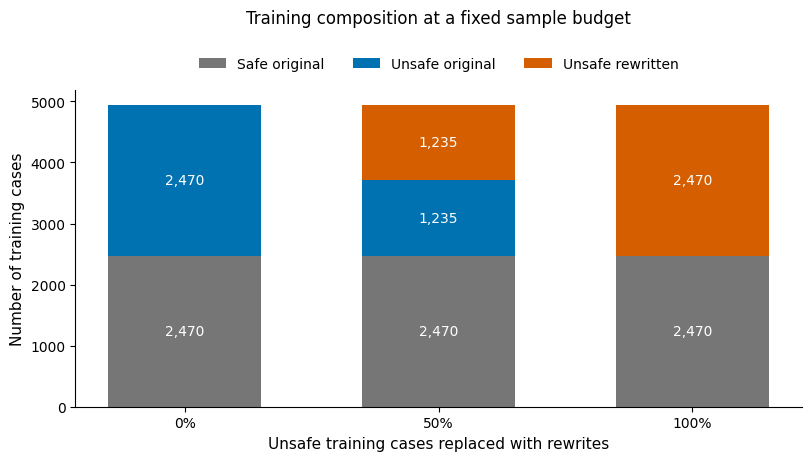

In [77]:
with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
}):
    plot_data = conditions.sort_values("rewrite_ratio").copy()
    x = np.arange(len(plot_data))

    safe_counts = (
        plot_data["training_cases"] - plot_data["unsafe_cases"]
    )
    original_unsafe = (
        plot_data["unsafe_cases"] - plot_data["rewritten_unsafe"]
    )
    rewritten_unsafe = plot_data["rewritten_unsafe"]

    fig1, ax = plt.subplots(
        figsize=(8, 4.5),
        constrained_layout=True
    )
    bottom = np.zeros(len(plot_data))

    for values, label, color in [
        (safe_counts, "Safe original", "#767676"),
        (original_unsafe, "Unsafe original", "#0072B2"),
        (rewritten_unsafe, "Unsafe rewritten", "#D55E00")
    ]:
        ax.bar(
            x,
            values,
            bottom=bottom,
            label=label,
            color=color,
            width=0.6
        )

        for position, value, base in zip(x, values, bottom):
            if value > 0:
                ax.text(
                    position,
                    base + value / 2,
                    f"{value:,}",
                    ha="center",
                    va="center",
                    color="white",
                    fontsize=10
                )

        bottom += values.to_numpy()

    ax.set_xticks(
        x,
        [f"{ratio:.0%}" for ratio in plot_data["rewrite_ratio"]]
    )
    ax.set(
        xlabel="Unsafe training cases replaced with rewrites",
        ylabel="Number of training cases",
        ylim=(0, plot_data["training_cases"].max() * 1.05)
    )

    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=3,
        frameon=False
    )
    ax.set_title(
        "Training composition at a fixed sample budget",
        pad=48
    )

    fig1.savefig(
        RESULTS / "figure_1_training_composition.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

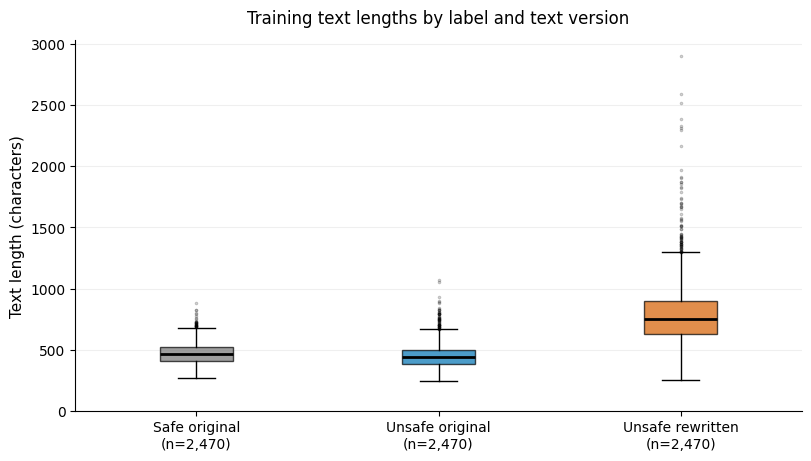

The two unsafe groups are paired versions of the same training cases.
Boxes show the middle 50%; whiskers extend to 1.5 IQR; dots show outliers.


,group,median_characters
0,Safe original,463.0
1,Unsafe original,440.0
2,Unsafe rewritten,751.0


In [78]:
with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
}):
    safe_train = train.loc[
        train["label"] == 0,
        "original_text"
    ].str.len()

    unsafe_original = train.loc[
        train["label"] == 1,
        "original_text"
    ].str.len()

    unsafe_rewritten = train.loc[
        train["label"] == 1,
        "rewritten_text"
    ].str.len()

    lengths = [
        safe_train,
        unsafe_original,
        unsafe_rewritten
    ]
    labels = [
        f"Safe original\n(n={len(safe_train):,})",
        f"Unsafe original\n(n={len(unsafe_original):,})",
        f"Unsafe rewritten\n(n={len(unsafe_rewritten):,})"
    ]

    fig3, ax = plt.subplots(
        figsize=(8, 4.5),
        constrained_layout=True
    )

    boxes = ax.boxplot(
        lengths,
        tick_labels=labels,
        patch_artist=True,
        medianprops={
            "color": "black",
            "linewidth": 2
        },
        flierprops={
            "marker": ".",
            "markersize": 3,
            "alpha": 0.25
        }
    )

    for box, color in zip(
        boxes["boxes"],
        ["#767676", "#0072B2", "#D55E00"]
    ):
        box.set_facecolor(color)
        box.set_alpha(0.7)

    ax.set(
        ylabel="Text length (characters)",
        ylim=(0, None)
    )
    ax.set_title(
        "Training text lengths by label and text version",
        pad=12
    )
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

    fig3.savefig(
        RESULTS / "figure_3_training_lengths.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print(
    "The two unsafe groups are paired versions "
    "of the same training cases."
)
print(
    "Boxes show the middle 50%; whiskers extend "
    "to 1.5 IQR; dots show outliers."
)

display(pd.DataFrame({
    "group": [
        "Safe original",
        "Unsafe original",
        "Unsafe rewritten"
    ],
    "median_characters": [
        values.median() for values in lengths
    ]
}))

## 6. Metrics and validation evaluation

Unsafe recall = TP / (TP + FN).
Safe false-positive rate = FP / (FP + TN).

The rewritten test view replaces unsafe texts only. Safe texts remain identical.

The always-safe baseline has recall 0 and false-positive rate 0. This illustrates
why a low false-positive rate alone is not sufficient.

No tuning is performed. The threshold remains 0.5.

In [79]:
def evaluate(frame, split_name):
    summaries, predictions = [], []

    for view in ["original", "rewritten"]:
        texts = frame["original_text"].copy()
        unsafe = frame.label == 1

        if view == "rewritten":
            texts.loc[unsafe] = frame.loc[
                unsafe, "rewritten_text"
            ]

        for ratio in [None] + RATIOS:
            if ratio is None:
                scores = np.zeros(len(frame))
            else:
                scores = models[ratio].predict_proba(texts)[:, 1]

            predicted = (scores >= THRESHOLD).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                frame.label, predicted, labels=[0, 1]
            ).ravel()

            model_name = (
                "always_safe" if ratio is None else "tfidf_lr"
            )

            summaries.append({
                "split": split_name,
                "model": model_name,
                "rewrite_ratio": ratio,
                "view": view,
                "unsafe_recall": tp / (tp + fn),
                "safe_fpr": fp / (fp + tn),
                "auc": roc_auc_score(frame.label, scores),
                "tp": int(tp),
                "fn": int(fn),
                "fp": int(fp),
                "tn": int(tn)
            })

            predictions.extend({
                "case_id": case,
                "model": model_name,
                "rewrite_ratio": ratio,
                "view": view,
                "label": int(label),
                "unsafe_score": float(score),
                "prediction": int(prediction)
            } for case, label, score, prediction in zip(
                frame.case_id, frame.label, scores, predicted
            ))

    return pd.DataFrame(summaries), pd.DataFrame(predictions)

validation_results, validation_predictions = evaluate(
    splits["validation"], "validation"
)

display(validation_results.round(4))
print("The threshold remains fixed at 0.5 for every condition.")

,split,model,rewrite_ratio,view,unsafe_recall,safe_fpr,auc,tp,fn,fp,tn
0,validation,always_safe,NaN,original,0.0000,0.0000,0.5000,0,525,0,525
1,validation,tfidf_lr,0.0,original,0.9924,0.0229,0.9992,521,4,12,513
2,validation,tfidf_lr,0.5,original,0.9790,0.0267,0.9983,514,11,14,511
3,validation,tfidf_lr,1.0,original,0.5010,0.0076,0.9827,263,262,4,521
4,validation,always_safe,NaN,rewritten,0.0000,0.0000,0.5000,0,525,0,525
5,validation,tfidf_lr,0.0,rewritten,0.8019,0.0229,0.9816,421,104,12,513
6,validation,tfidf_lr,0.5,rewritten,0.9943,0.0267,0.9993,522,3,14,511
7,validation,tfidf_lr,1.0,rewritten,0.9905,0.0076,0.9997,520,5,4,521


The threshold remains fixed at 0.5 for every condition.


## 7. Evaluate the fixed test split

Evaluate all predeclared conditions without selecting a winner or changing
the threshold.

The main outcomes are unsafe recall and safe false-positive rate. AUC is
secondary.

Safe FPR must match between the two views because the safe texts are identical.

In [80]:
test_results, test_predictions = evaluate(
    splits["test"], "test"
)

lr_results = test_results[
    test_results.model == "tfidf_lr"
]

assert (
    lr_results.groupby("rewrite_ratio")["safe_fpr"]
    .nunique().eq(1).all()
)

assert (test_results.tp + test_results.fn).eq(535).all()
assert (test_results.fp + test_results.tn).eq(535).all()

display(test_results.round(4))

,split,model,rewrite_ratio,view,unsafe_recall,safe_fpr,auc,tp,fn,fp,tn
0,test,always_safe,NaN,original,0.0000,0.0000,0.5000,0,535,0,535
1,test,tfidf_lr,0.0,original,0.9925,0.0187,0.9986,531,4,10,525
2,test,tfidf_lr,0.5,original,0.9757,0.0150,0.9978,522,13,8,527
3,test,tfidf_lr,1.0,original,0.4729,0.0000,0.9819,253,282,0,535
4,test,always_safe,NaN,rewritten,0.0000,0.0000,0.5000,0,535,0,535
5,test,tfidf_lr,0.0,rewritten,0.7981,0.0187,0.9816,427,108,10,525
6,test,tfidf_lr,0.5,rewritten,0.9963,0.0150,0.9995,533,2,8,527
7,test,tfidf_lr,1.0,rewritten,0.9963,0.0000,0.9999,533,2,0,535


## 8. Plot the pilot

All rates are percentages.

The left panel shows recall for each unsafe text version.
The right panel shows one FPR curve because safe texts do not change.

Only three ratios are tested. Connecting lines are visual guides.

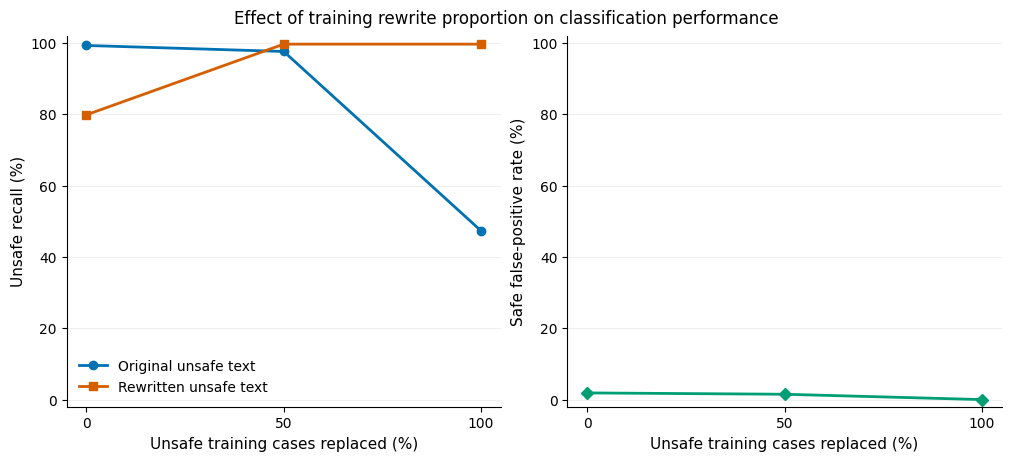

In [81]:
with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
}):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(10, 4.5),
        constrained_layout=True
    )

    for view, color, marker in [
        ("original", "#0072B2", "o"),
        ("rewritten", "#D55E00", "s")
    ]:
        part = lr_results.loc[
            lr_results["view"] == view
        ].sort_values("rewrite_ratio")

        axes[0].plot(
            part["rewrite_ratio"] * 100,
            part["unsafe_recall"] * 100,
            color=color,
            marker=marker,
            linewidth=2,
            markersize=6,
            label=f"{view.title()} unsafe text"
        )

    part = lr_results.loc[
        lr_results["view"] == "original"
    ].sort_values("rewrite_ratio")

    axes[1].plot(
        part["rewrite_ratio"] * 100,
        part["safe_fpr"] * 100,
        color="#009E73",
        marker="D",
        linewidth=2,
        markersize=6
    )

    axes[0].set_ylabel("Unsafe recall (%)")
    axes[1].set_ylabel("Safe false-positive rate (%)")

    for ax in axes:
        ax.set(
            xlabel="Unsafe training cases replaced (%)",
            xticks=[0, 50, 100],
            ylim=(-2, 102)
        )
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)

    axes[0].legend(
        frameon=False,
        loc="lower left"
    )

    fig.suptitle(
        "Effect of training rewrite proportion on classification performance",
        fontsize=12
    )

    fig.savefig(
        RESULTS / "pilot_results.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

## 9. Save Reproducible Outputs

The ZIP contains:

- Data files for manual Hugging Face upload.
- Pilot results and configuration files for manual GitHub upload.

No remote repository is changed.

Write the dataset card and your interpretation yourself, following the course Human-Only requirement.

Source: [PolyGuard dataset](https://huggingface.co/datasets/Virtue-AI-HUB/PolyGuard), CC BY 4.0.

Cite the [associated NeurIPS 2025 paper](https://proceedings.nips.cc/paper_files/paper/2025/hash/11ed9cdc955e23684a1beae9cb8da059-Abstract-Datasets_and_Benchmarks_Track.html).

Before interpreting results, consider:

- Which condition misses fewer unsafe cases?
- Does it increase false alarms?
- Are differences stable across repeated splits?

Do not infer real-world reliability from this single synthetic-data pilot.

In [82]:
for name, table in [
    ("validation_results", validation_results),
    ("test_results", test_results),
    ("validation_predictions", validation_predictions),
    ("test_predictions", test_predictions),
    ("training_conditions", conditions),
    ("training_assignments", pd.DataFrame(assignments))
]:
    table.to_csv(
        RESULTS / f"{name}.csv",
        index=False
    )

provenance = {
    "source_repo": REPO,
    "source_revision": REVISION,
    "source_license": "cc-by-4.0",
    "seed": SEED,
    "held_out_unit": "normalized rule",
    "input_files": raw_manifest,
    "split_counts": {
        name: {
            "cases": len(frame),
            "rules": int(frame.rule_id.nunique())
        }
        for name, frame in splits.items()
    },
    "limitations": [
        "Synthetic examples",
        "No expert label audit",
        "Exploratory split"
    ]
}

(DATA / "provenance.json").write_text(
    json.dumps(provenance, indent=2),
    encoding="utf-8"
)

config = {
    "ratios": RATIOS,
    "seed": SEED,
    "threshold": THRESHOLD,
    "model": models[0.0].get_params()[
        "logisticregression"
    ].get_params(),
    "tfidf": {
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_features": 15000,
        "sublinear_tf": True
    },
    "python": sys.version,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "requests": requests.__version__
}

(RESULTS / "experiment_config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8"
)

archive = ROOT.parent / "polyguard_colab_outputs"
staging = ROOT / "export"

for name, source in [
    ("data", DATA),
    ("results", RESULTS)
]:
    shutil.copytree(
        source,
        staging / name,
        dirs_exist_ok=True
    )

archive_path = shutil.make_archive(
    str(archive),
    "zip",
    root_dir=staging
)

print("Saved:", archive_path)
print(
    "Hugging Face: manually upload data/*.jsonl "
    "and data/provenance.json."
)
print(
    "GitHub: manually upload this notebook "
    "and the pilot results."
)

Saved: /content/assignment/4/polyguard_colab_outputs.zip
Hugging Face: manually upload data/*.jsonl and data/provenance.json.
GitHub: manually upload this notebook and the pilot results.


## 10. Download the Output Archive

In Colab, this cell downloads the ZIP to your computer.

Also use File > Download > Download .ipynb to save the notebook with your own executed outputs.

Uploading files to the course repositories remains a manual step.

In [83]:
from pathlib import Path
from datetime import datetime, timezone
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

required_figures = [
    "figure_1_training_composition.png",
    "figure_2_source_coverage.png",
    "figure_3_training_lengths.png",
    "figure_4_pilot_results.png",
]

missing = [
    name for name in required_figures
    if not (RESULTS / name).is_file()
]

if missing:
    raise FileNotFoundError(
        "Run all plotting cells first. Missing: "
        + ", ".join(missing)
    )

timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_UTC")
download_path = ROOT.parent / f"polyguard_outputs_{timestamp}.zip"

with ZipFile(download_path, "w", compression=ZIP_DEFLATED) as archive:
    for folder_name, folder_path in [
        ("data", DATA),
        ("results", RESULTS)
    ]:
        for file_path in sorted(Path(folder_path).rglob("*")):
            if file_path.is_file():
                archive.write(
                    file_path,
                    arcname=str(
                        Path(folder_name)
                        / file_path.relative_to(folder_path)
                    )
                )

print(f"Created: {download_path}")
print(f"Size: {download_path.stat().st_size / 1024**2:.2f} MB")

files.download(str(download_path))

Created: /content/assignment/4/polyguard_outputs_20261122_103015_UTC.zip
Size: 4.19 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>